# Integración numérica

In [1]:
# Librerías utilizadas en este capítulo
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid, simpson, fixed_quad, quad
from pathlib import Path
from IPython.display import HTML

## Introducción
El cálculo de integrales aparece en todos los problemas de ingeniería. Muchos ejemplos tienen relación directa con la estimación de áreas: (a) la superficie de un campo limitado por dos carreteras y un río, (b) el área transversal de un canal, (c) la fuerza de arrastre del viento sobre un edificio.

<img src="./images/integration_examples.png" width="600px" align= center>

En este capítulo revisaremos dos familias de métodos, según la información disponible:
1. **Datos tabulados** de una función desconocida, como la tabla anterior: fórmulas de Newton-Cotes.
2. **Una función conocida**, que podemos evaluar donde queramos: cuadratura de Gauss y cuadratura adaptativa.

## Integración de datos tabulados (fórmulas de Newton-Cotes)

Consideremos el trabajo que realiza una fuerza variable $F(x)$ sobre un bloque, cuando además cambia el ángulo $\theta(x)$ entre la fuerza y la dirección del movimiento:

\begin{equation*}
W = \int_{0}^{30} F(x)\cos\theta(x)\,dx
\end{equation*}

No conocemos $F(x)$ ni $\theta(x)$ como fórmula. Solo tenemos mediciones cada 5 ft:

| $x$ (ft) | 0 | 5 | 10 | 15 | 20 | 25 | 30 |
|---|---|---|---|---|---|---|---|
| $F$ (lb) | 0.0 | 9.0 | 13.0 | 14.0 | 10.5 | 12.0 | 5.0 |
| $\theta$ (rad) | 0.50 | 1.40 | 0.75 | 0.90 | 1.30 | 1.48 | 1.50 |

Queremos aproximar la integral de una función $f(x)$ en el intervalo $x\in[a,b]$:

\begin{equation*}
\int_a^b f(x)\,dx
\end{equation*}

La función es desconocida y solo contamos con los datos tabulados $x_i$ y $f(x_i)$.

Asumamos:
- Intervalo discretizado por $n+1$ puntos $\{x_0, x_1, \ldots, x_n\}$, con $x_0 = a$ y $x_n = b$.
- Subintervalo entre dos puntos $x_i$ y $x_{i+1}$ de ancho $h_i = x_{i+1} - x_{i}$.
- Valores $\{f(x_0), f(x_1), \ldots, f(x_n)\}$ conocidos.

Las fórmulas de Newton-Cotes reemplazan $f(x)$ por el polinomio de interpolación $p_n(x)$ de los datos, que es fácil de integrar:

\begin{equation*}
\int_a^b f(x)\,dx \approx \int_a^b p_n(x)\,dx
\end{equation*}

Un polinomio de grado 0 (constante) da la regla de Riemann, uno de grado 1 (recta) la regla del trapecio y uno de grado 2 (parábola) la regla de Simpson.

<img src="./images/Newton_cotes.png" width="600px" align= center>

>En la **Unidad 4** aproximamos datos por un polinomio $p_n(x)$ que pasa por ellos. Un polinomio se integra de forma exacta. En la **Unidad 5** vimos que el término descartado de la serie de Taylor fija el error. Integrar numéricamente es juntar las dos ideas: integrar el interpolante y medir el error con Taylor.

### Integral de Riemann

El caso más sencillo consiste en aproximar $f(x)$ en el subintervalo $x\in[x_i, x_{i+1}]$ mediante un polinomio de grado 0. La elección más lógica es $f(x) \approx f(x_i)$ o $f(x) \approx f(x_{i+1})$, ya que estos valores son conocidos.

Matemáticamente:

\begin{equation*}
\int_a^b f(x) dx \approx \sum_{i = 0}^{n-1} h_if(x_i)\quad\mathrm{o}\quad\approx\sum_{i = 1}^{n} h_if(x_i),
\end{equation*}

dependiendo de si tomamos el valor de la izquierda o derecha del tramo, respectivamente.

En otras palabras, aproximamos el área bajo cada subintervalo mediante un rectángulo. 

<img src="./images/riemann_integral.png" width="400px" align= center>

Mediante series de Taylor podemos caracterizar el error de esta aproximación. Por simplicidad, consideramos un conjunto de $n+1$ puntos igualmente espaciados con $h_i = h = \frac{b-a}{n}$. 

Considerando la integral en subintervalos de ancho $h$, podemos expresar la integral como:

\begin{equation*}
\int_a^b f(x) dx = \sum_{i = 0}^{n-1} \int_{x_i}^{x_{i+1}} f(x) dx,
\end{equation*}

Luego, para cada subintervalo $x\in[x_i, x_{i+1}]$, consideremos la expansión de Taylor de $f(x)$ centrada en $x_i$:

\begin{equation*}
f(x) = f(x_i) + f^{\prime}(x_i)(x-x_i) + \cdots
\end{equation*}

Integrando en cada subintervalo $x\in[x_i, x_{i+1}]$:

\begin{align*}
\int_{x_i}^{x_{i+1}}f(x)\,dx &= hf(x_i) + \frac{h^2}{2}f^{\prime}(x_i) + O(h^3) \\
&= hf(x_i) + O(h^2)
\end{align*}

Sumando los $n$ subintervalos, el error de truncamiento es $n\,O(h^2)$. Como $n = (b-a)/h$, la regla de Riemann tiene un error de truncamiento global $O(h)$:

\begin{equation*}
\int_a^b f(x)\,dx = \sum_{i = 0}^{n-1} hf(x_i) + O(h)
\end{equation*}

### Regla del trapecio (`scipy.integrate.trapezoid`)
Podemos mejorar la aproximación conservando un término más de la serie de Taylor:

\begin{equation*}
f(x) = f(x_i) + f^{\prime}(x_i)(x-x_i) + O(h^2)
\end{equation*}

Integrando en el subintervalo $x\in[x_i, x_{i+1}]$:

\begin{equation*}
\int_{x_i}^{x_{i+1}}f(x)\,dx = hf(x_i) + \frac{h^2}{2}f^{\prime}(x_i) + O(h^3)
\end{equation*}

Aproximando la derivada por la pendiente entre los dos puntos, $f^{\prime}(x_i) = \frac{f(x_{i+1}) - f(x_i)}{h} + O(h)$, obtenemos la **regla del trapecio**:

\begin{equation*}
\int_{x_i}^{x_{i+1}}f(x)\,dx = h\left[\frac{f(x_i) + f(x_{i+1})}{2}\right] + O(h^3)
\end{equation*}

>**Importante.** Con la derivada aproximada de esta forma, $f(x_i) + f^{\prime}(x_i)(x-x_i)$ es la recta $p_1(x)$ que pasa por $(x_i, f(x_i))$ y $(x_{i+1}, f(x_{i+1}))$. **La regla del trapecio** integra esa recta y, por lo tanto, **es exacta cuando $f(x)$ es una recta.**

Considerando un conjunto de $n+1$ puntos igualmente espaciados en el intervalo $x\in[a,b]$, la **regla del trapecio *extendida o compuesta*** es:

\begin{equation*}
\int_a^b f(x)\,dx = \sum_{i = 0}^{n-1} h\left[\frac{f(x_i) + f(x_{i+1})}{2}\right] + O(h^2),
\end{equation*}

donde $h = (b-a)/n$. Igual que en la regla de Riemann, al sumar los $n$ subintervalos el error de truncamiento baja de $O(h^3)$ a $O(h^2)$.

<img src="./images/trapezoid_rule.png" width="400px" align= center>

En Python tenemos la función `trapezoid` de la librería `scipy.integrate`.

Para utilizar la función debemos indicar los valores de $f(x_i)$ (variable `yi`) en el primer argumento de la función y los $x_i$ (variable `xi`) en el segundo:
```python
from scipy.integrate import trapezoid
int_trpz = trapezoid(yi, xi)  # integral de f(x) mediante regla del trapecio
```

>**Nota.**`trapezoid` no requiere que los valores de `xi` estén igualmente espaciados. Basta con entregar el arreglo `xi` correspondiente.

Más información en la [documentación oficial](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.trapezoid.html#scipy.integrate.trapezoid)

Calculemos el trabajo de la fuerza variable con los 7 datos de la tabla:

In [2]:
xi    = np.array([0, 5, 10, 15, 20, 25, 30])                  # posición (ft)
F     = np.array([0.0, 9.0, 13.0, 14.0, 10.5, 12.0, 5.0])     # fuerza (lb)
theta = np.array([0.50, 1.40, 0.75, 0.90, 1.30, 1.48, 1.50])  # ángulo (rad)
yi = F*np.cos(theta)                                          # integrando

W_trpz = trapezoid(yi, xi)
print(f'Trabajo, regla del trapecio: {W_trpz:.2f} lb·ft')

Trabajo, regla del trapecio: 119.09 lb·ft


### Regla de Simpson 1/3 (`scipy.integrate.simpson`)

En términos generales, lo que hicimos en la regla del trapecio y Riemann es aproximar $f(x)$ por un polinomio y luego integrarlo en cada subintervalo $x\in[x_i, x_{i+1}]$. El error de truncamiento disminuye a medida que aumentamos el orden del polinomio.

El siguiente paso, entonces, es aproximar $f(x)$ por la parábola $p_2(x)$ que pasa por tres puntos consecutivos, $x_{i-1}$, $x_i$ y $x_{i+1}$.

La regla de Simpson sigue esta lógica, aunque utilizando **polinomios de interpolación de Lagrange** en lugar de expansiones de Taylor.

Por ejemplo, la regla de Simpson 1/3 considera polinomios de Lagrange de segundo orden:

\begin{align*}
p_2(x) = \;& f(x_{i-1})\frac{(x - x_i)(x - x_{i+1})}{(x_{i-1} - x_i)(x_{i-1} - x_{i+1})} + f(x_i)\frac{(x - x_{i-1})(x - x_{i+1})}{(x_{i} - x_{i-1})(x_{i} - x_{i+1})} \\
&+ f(x_{i+1})\frac{(x - x_{i-1})(x - x_{i})}{(x_{i+1} - x_{i-1})(x_{i+1} - x_{i})}
\end{align*}

Al integrar el polinomio en el subintervalo $x\in [x_{i-1}, x_{i+1}]$ obtenemos la **regla de Simpson 1/3**:

\begin{equation*}
\int_{x_{i-1}}^{x_{i+1}} f(x)\,dx = \frac{h}{3}\left[f(x_{i-1}) + 4f(x_i) + f(x_{i+1})\right] + O(h^5)
\end{equation*}

>**Importante.** El polinomio es de grado 2, pero el error es $O(h^5)$ y no $O(h^4)$. Al integrar entre $x_{i-1}$ y $x_{i+1}$, simétricos respecto a $x_i$, el término cúbico de la serie de Taylor se cancela. Por eso la regla de Simpson 1/3 es exacta para polinomios de hasta grado 3.

Para un conjunto de $n+1$ puntos igualmente espaciados en el intervalo $x\in[a,b]$, la **regla de Simpson 1/3 *extendida o compuesta*** es:

\begin{equation*}
\int_a^b f(x)\,dx \approx \frac{h}{3} \left[f(x_0)+4 \sum_{i\ \text{impar}}f(x_i)+2 \sum_{i\ \text{par}}f(x_i)+f(x_n)\right] + O(h^4)
\end{equation*}

donde las sumas recorren los puntos interiores, $i = 1, \ldots, n-1$.

<img src="./images/simpson_rule.png" width="400px" align= center>

>**Importante.** La regla de Simpson 1/3 usa los subintervalos de a pares. Por eso **el número de puntos debe ser impar**.

En Python tenemos la función `simpson` de la librería `scipy.integrate`.

Los argumentos son los mismos de `trapezoid`, aunque `xi` se entrega con nombre:
```python
from scipy.integrate import simpson
int_simp = simpson(yi, x=xi)  # integral de f(x) mediante regla de Simpson 1/3
```

La función `simpson` tampoco requiere que los puntos `xi` estén igualmente espaciados ni que sean un número impar.

**Si el número de puntos `xi` es par**, `simpson` aplica la regla de Simpson a los primeros $n-1$ subintervalos y agrega una corrección parabólica para el último. El resultado sigue siendo bueno, aunque pierde precisión respecto al caso impar.

Más información en la [documentación oficial](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.simpson.html#scipy.integrate.simpson)

Comparemos con $\int_0^\pi \sin(x)\,dx = 2$, usando 10, 11 y 12 puntos igualmente espaciados:

In [3]:
for n_pts in [10, 11, 12]:
    xi_s = np.linspace(0, np.pi, n_pts)
    int_simp = simpson(np.sin(xi_s), x=xi_s)
    print(f'Simpson 1/3 ({n_pts} puntos): {int_simp:.6f}, error absoluto {abs(2 - int_simp):.2e}')

Simpson 1/3 (10 puntos): 2.000749, error absoluto 7.49e-04
Simpson 1/3 (11 puntos): 2.000110, error absoluto 1.10e-04
Simpson 1/3 (12 puntos): 2.000341, error absoluto 3.41e-04


>Con 12 puntos el error es mayor que con 11, aunque usamos más datos. El subintervalo que queda sin pareja se integra con una fórmula de menor orden y ese tramo domina el error.

Volvamos al trabajo de la fuerza variable. Con los 7 datos (6 subintervalos), Simpson se puede aplicar directamente:

In [4]:
W_simp = simpson(yi, x=xi)
W_ref = 129.52  # estimado con datos cada 1 ft (Chapra y Canale, §24.4)

print(f'Trapecio:    {W_trpz:.2f} lb·ft, error relativo {abs(W_trpz - W_ref)/W_ref*100:.1f} %')
print(f'Simpson 1/3: {W_simp:.2f} lb·ft, error relativo {abs(W_simp - W_ref)/W_ref*100:.1f} %')

Trapecio:    119.09 lb·ft, error relativo 8.1 %
Simpson 1/3: 117.13 lb·ft, error relativo 9.6 %


Simpson, un método de mayor orden, da un resultado **peor** que el trapecio. El orden $O(h^n)$ describe cómo baja el error cuando $h$ es pequeño respecto a la distancia en que $f(x)$ cambia de forma, por ejemplo entre un máximo y un mínimo. Con mediciones cada 5 ft perdemos dos máximos del integrando, cerca de $x = 2.5$ y $x = 12.5$ ft, y ninguna fórmula los puede recuperar.

**¿Cómo sabemos si $h$ es suficientemente pequeño?** El valor numérico de $h$ no sirve como criterio: depende de las unidades (5 ft son 60 pulgadas). 

Un criterio práctico es calcular la integral con todos los datos (paso $h$) y con uno de cada dos (paso $2h$). Si el resultado cambia más que la precisión que necesitamos, los datos no resuelven la función.

In [5]:
W_2h = trapezoid(yi[::2], xi[::2])   # uno de cada dos datos: paso 2h = 10 ft
print(f'Trapecio, paso h  = 5 ft:  {W_trpz:.2f} lb·ft')
print(f'Trapecio, paso 2h = 10 ft: {W_2h:.2f} lb·ft')
print(f'Cambio relativo: {abs(W_2h - W_trpz)/W_trpz*100:.1f} %')

Trapecio, paso h  = 5 ft:  119.09 lb·ft
Trapecio, paso 2h = 10 ft: 124.98 lb·ft
Cambio relativo: 4.9 %


>El resultado cambia 4.9 % al duplicar $h$. Con esa diferencia no podemos garantizar ni la segunda cifra del trabajo, y cambiar de trapecio a Simpson no lo arregla. La mejora viene de medir más puntos.

Cuando $h$ sí es pequeño, los órdenes se cumplen. Verifiquémoslo con $\int_0^\pi \sin(x)\,dx = 2$, reduciendo $h$ a la mitad sucesivamente.

In [6]:
n_arr = 2**np.arange(1, 10)        # número de subintervalos (par)
h_arr = np.pi/n_arr
E_trpz, E_simp = [], []
for n in n_arr:
    xi_s = np.linspace(0, np.pi, n + 1)
    E_trpz.append(abs(2 - trapezoid(np.sin(xi_s), xi_s)))
    E_simp.append(abs(2 - simpson(np.sin(xi_s), x=xi_s)))

Si el error es $E \approx Ch^n$, entonces $\log E \approx \log C + n\log h$: el orden $n$ es la pendiente de una recta, y lo obtenemos con un ajuste lineal (`polyfit`, **Unidad 3**).

In [7]:
# ajuste lineal en escala log-log: la pendiente es el orden del error
a_trpz = np.polyfit(np.log(h_arr), np.log(E_trpz), 1)
a_simp = np.polyfit(np.log(h_arr), np.log(E_simp), 1)
print(f'Orden del trapecio:    {a_trpz[0]:.2f}')
print(f'Orden de Simpson 1/3:  {a_simp[0]:.2f}')


Orden del trapecio:    2.01
Orden de Simpson 1/3:  4.04


Mostramos los resultados en un gráfico con las líneas de tendencia obtenidas por el modelo de regresión.

In [8]:
%%capture simp_vs_trapz
# gráfico
plt.figure(figsize=(5, 3))
plt.loglog(h_arr, E_trpz, 'o', color='tab:blue', label='Trapecio')
plt.loglog(h_arr, E_simp, 's', color='tab:orange', label='Simpson 1/3')
plt.loglog(h_arr, np.exp(np.polyval(a_trpz, np.log(h_arr))), '-', color='tab:blue',
           label=f'ajuste, pendiente {a_trpz[0]:.2f}')
plt.loglog(h_arr, np.exp(np.polyval(a_simp, np.log(h_arr))), '-', color='tab:orange',
           label=f'ajuste, pendiente {a_simp[0]:.2f}')
plt.xlabel('$h$')
plt.ylabel('Error absoluto')
plt.grid(True, which='both', alpha=0.3)
plt.legend(fontsize=8)
plt.show()

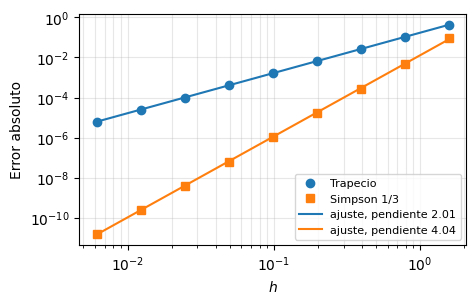

In [9]:
simp_vs_trapz()

>Las pendientes son 2.01 y 4.04, los órdenes $O(h^2)$ y $O(h^4)$ de las reglas compuestas. Cada vez que $h$ se reduce a la mitad, el error del trapecio baja 4 veces y el de Simpson 16 veces.

## Integración de funciones conocidas
Las fórmulas de Newton-Cotes son útiles cuando no conocemos la función y solo disponemos de datos tabulados.

Si la función es conocida, podemos elegir dónde evaluarla. El costo de una integral pasa a medirse en **número de evaluaciones de $f(x)$**, y hay métodos que lo aprovechan mejor que Newton-Cotes.

Usaremos como ejemplo la función de gibas (*humps*, Chapra y Canale, problemas 18.27 y 25.23), con dos máximos de distinto ancho:

\begin{equation*}
f(x) = \frac{1}{(x-0.3)^2 + 0.01} + \frac{1}{(x-0.9)^2+0.04} - 6, \qquad \int_0^1 f(x)\,dx = 29.858325\ldots
\end{equation*}

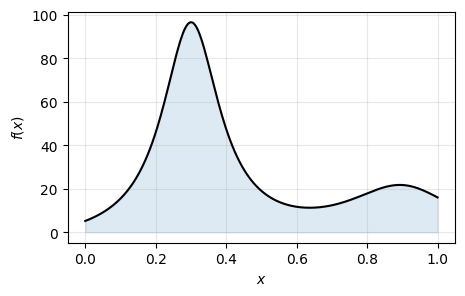

In [10]:
humps = lambda x: 1/((x - 0.3)**2 + 0.01) + 1/((x - 0.9)**2 + 0.04) - 6
I_humps = 29.85832539549867      # valor exacto

x = np.linspace(0, 1, 300)
plt.figure(figsize=(5, 3))
plt.plot(x, humps(x), 'k')
plt.fill_between(x, humps(x), color='tab:blue', alpha=0.15)
plt.xlabel('$x$')
plt.ylabel('$f(x)$')
plt.grid(alpha=0.3)
plt.show()

### Cuadratura de Gauss (`scipy.integrate.fixed_quad`)
En la regla del trapecio aproximamos la integral por el área bajo una recta que conecta los extremos del intervalo. Si liberamos esos dos puntos, podemos buscar la recta que equilibre el área que sobra con el área que falta.

Comprobemoslo en la siguiente animación, moviendo los dos puntos por los que pasa la recta y buscando la posición que hace el error más pequeño. Partamos con la cúbica y con los puntos simétricos.

In [11]:
HTML(Path('interactive/A2_trapecio_a_gauss.html').read_text(encoding='utf-8'))

>**Nota.** El polinomio de grado 5 es el ejemplo de Chapra y Canale (ejemplos 21.1 y 22.3): $p(t) = 0.2 + 25t - 200t^2 + 675t^3 - 900t^4 + 400t^5$, integrado entre $t = 0$ y $t = 0.8$, con valor exacto 1.640533. En la animación aparece llevado al intervalo $[-1, 1]$ con el cambio de variable que veremos más adelante.

En la animación, vemos que para la cúbica existe una posición de los puntos, $x = \pm 0.577$, que entrega la integral **exacta**. La misma posición no es exacta para las otras dos funciones, pero reduce el error del trapecio de 89.5 % a 11.1 % para el polinomio de grado 5 y de 31.3 % a 0.33 % para $e^x$.

Formalicemos lo que encontramos en la animación. Consideremos la forma general para aproximar una integral en el intervalo $x\in[-1,1]$ mediante dos puntos $x_0$ y $x_1$:

\begin{equation*}
\int_{-1}^{1} f(x)\,dx \approx c_0f(x_0) + c_1f(x_1)
\end{equation*}

En la regla del trapecio tenemos $x_0 = -1$, $x_1 = 1$ y $c_0=c_1=1$. Esta fórmula es exacta para polinomios de grado 1.

Si liberamos $c_0$, $c_1$, $x_0$ y $x_1$, tenemos un problema con 4 incógnitas.

Necesitamos 4 condiciones. Así, aproximaremos la función a un polinomio de grado 3, de la forma $f(x)\approx a_0 + a_1x + a_2x^2 + a_3x^3$, donde $a_0, a_1, a_2, a_3$ son coeficientes a determinar.



Imponemos que la fórmula sea exacta para $f(x) = 1$, $x$, $x^2$ y $x^3$, lo que da como resultado un sistema de ecuaciones para $c_0$, $c_1$, $x_0$ y $x_1$:

\begin{align*}
c_0 + c_1 &= \int_{-1}^{1} 1\,dx = 2 \\
c_0x_0 + c_1x_1 &= \int_{-1}^{1} x\,dx = 0 \\
c_0x_0^2 + c_1x_1^2 &= \int_{-1}^{1} x^2\,dx = 2/3 \\
c_0x_0^3 + c_1x_1^3 &= \int_{-1}^{1} x^3\,dx = 0
\end{align*}

Su solución es $c_0 = c_1 = 1$, $x_0 = -1/\sqrt{3}$ y $x_1 = 1/\sqrt{3}$.

El resultado se conoce como **cuadratura de Gauss-Legendre de 2 puntos**:

\begin{equation*}
\int_{-1}^{1} f(x)\,dx = f\left(-\frac{1}{\sqrt{3}}\right) + f\left(\frac{1}{\sqrt{3}}\right) + O(h^5)
\end{equation*}

Con solo dos evaluaciones es exacta hasta polinomios de grado 3, igual que Simpson 1/3 con tres. Su error es del orden $O(h^5)$.

Mediante un procedimiento similar podemos generar fórmulas con más puntos. La siguiente tabla resume los pesos $c_i$ y los puntos de evaluación $x_i$, junto con su error de truncamiento:

<img src="./images/gaussian_quadrature_table.png" width="700px" align= center>

<center><small><b>Tabla 1.</b> Pesos y puntos de evaluación para la cuadratura de Gauss-Legendre</small></center>

>Con $n$ puntos, la cuadratura de Gauss es exacta para polinomios de hasta grado $2n-1$ y su error del orden $O(h^{2n + 1})$.

Las reglas de cuadratura de Gauss están definidas en $x\in[-1, 1]$. Para integrar en un intervalo $t\in[a,b]$ usamos el cambio de variable lineal:

\begin{equation*}
t = \frac{b+a}{2} + \frac{b-a}{2}x, \qquad dt = \frac{b-a}{2}dx
\end{equation*}

Así, la cuadratura de Gauss de $n$ puntos toma la forma:

\begin{equation*}
\int_{a}^{b} f(t)\,dt \approx \frac{b-a}{2}\sum_{i = 0}^{n-1} c_i f\left(\frac{b+a}{2} + \frac{b-a}{2}x_i\right)
\end{equation*}

donde $x_i$ y $c_i$ corresponden a los valores de la Tabla 1.

En ```python``` tenemos la función ```fixed_quad``` para cuadratura Gaussiana, implementada en la librería ```scipy.integrate```. 

Para calcular la cuadratura llamamos la función como `fixed_quad(f, a, b, n)[0]`, donde:
- `f`: función $f(x)$ en formato *callable*
- `a, b`: intervalo de integración $a$ y $b$
- `n`: número de puntos $n$ (`n=5` por defecto)

`fixed_quad` retorna un *tuple* de dos elementos. El primero es el valor de la integral, y por eso agregamos `[0]` al final.

Más información en la [documentación oficial](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.fixed_quad.html#scipy.integrate.fixed_quad)

Por ejemplo, con cuadratura de Gauss de 2 puntos:

\begin{equation*}
\int_0^\pi \sin(x)\,dx = 2
\end{equation*}

In [12]:
f = lambda x: np.sin(x)  # función tipo callable
a, b = 0, np.pi          # intervalo de integración

int_gauss = fixed_quad(f, a, b, n=2)[0]   # cuadratura de Gauss de 2 puntos
print(f'Gauss, 2 puntos: {int_gauss:.6f}')

Gauss, 2 puntos: 1.935820


Comparemos el error relativo de la cuadratura de Gauss y de la regla del trapecio a medida que aumentamos el número de evaluaciones de $f(x)$:

In [13]:
N = 10                      # máximo número de puntos
f = lambda x: np.sin(x)     # función tipo callable
a, b, I0 = 0, np.pi, 2      # intervalo y valor exacto

E_trpz, E_gauss = [], []
for n in range(2, N + 1):
    xi_f = np.linspace(a, b, n)
    E_trpz.append(abs(I0 - trapezoid(f(xi_f), xi_f))/I0)
    E_gauss.append(abs(I0 - fixed_quad(f, a, b, n=n)[0])/I0)

In [14]:
%%capture gauss_sinx
plt.figure(figsize=(5, 3))
plt.semilogy(range(2, N + 1), E_trpz, 'o:', color='tab:red', label='Trapecio')
plt.semilogy(range(2, N + 1), E_gauss, 'o:', color='tab:blue', label='Gauss')
plt.xlabel('número de evaluaciones de $f(x)$')
plt.ylabel('Error relativo')
plt.title(r'$\int_0^\pi \sin(x)\,dx = 2$')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

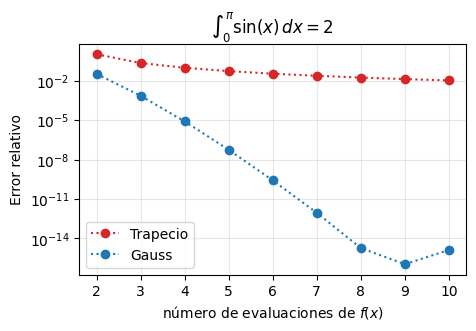

In [15]:
gauss_sinx()

>Con 8 evaluaciones, Gauss llega al error de máquina, mientras el error del trapecio sigue cerca de $10^{-2}$. Ubicar bien los puntos vale más que agregar puntos.

Repitamos la comparación con `humps`:

In [16]:
f, a, b, I0 = humps, 0, 1, I_humps

E_trpz, E_gauss = [], []
for n in range(2, N + 1):
    xi_f = np.linspace(a, b, n)
    E_trpz.append(abs(I0 - trapezoid(f(xi_f), xi_f))/I0)
    E_gauss.append(abs(I0 - fixed_quad(f, a, b, n=n)[0])/I0)

In [17]:
%%capture gauss_humps
fig, ax = plt.subplots(1,2, figsize=(10, 3))

x = np.linspace(0, 1, 300)
ax[0].plot(x, humps(x), 'k')
ax[0].fill_between(x, humps(x), color='tab:blue', alpha=0.15)
ax[0].set_xlabel('$x$')
ax[0].set_ylabel('$f(x)$')
ax[0].grid(alpha=0.3)
ax[0].set_title(r'humps(x)')

ax[1].semilogy(range(2, N + 1), E_trpz, 'o:', color='tab:red', label='Trapecio')
ax[1].semilogy(range(2, N + 1), E_gauss, 'o:', color='tab:blue', label='Gauss')
ax[1].set_xlabel('número de evaluaciones de $f(x)$')
ax[1].set_ylabel('Error relativo')
ax[1].set_title(r'$\int_0^1$ humps$(x)\,dx$')
ax[1].grid(alpha=0.3)
ax[1].legend()
plt.show()

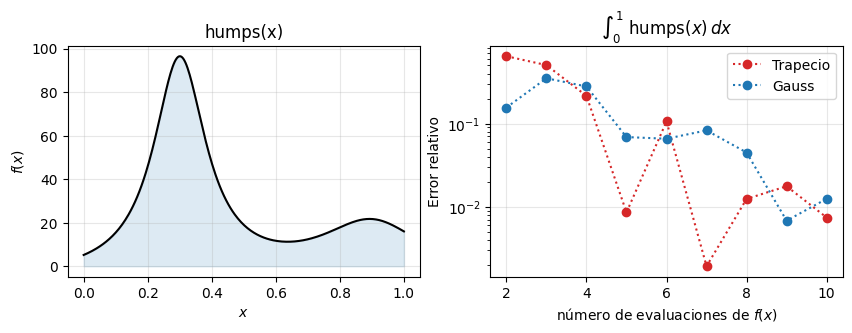

In [18]:
gauss_humps()

Con 10 evaluaciones, Gauss sigue sobre 1 % de error, no mejora de forma sistemática y en varios casos es peor que el trapecio. Un solo polinomio de grado alto no alcanza para describir dos máximos de distinto ancho.

>Gauss no es suficiente. Necesitamos concentrar las evaluaciones donde la función cambia rápido, y para decidir dónde, primero necesitamos estimar el error **sin conocer el valor exacto**.

### Estimación del error: extrapolación de Richardson
Calculemos la misma integral dos veces con la regla del trapecio, con paso $h$ y con paso $h/2$. Como el error del trapecio es $\approx Ch^2$:

\begin{align*}
I &\approx I(h) + Ch^2 \\
I &\approx I(h/2) + C\frac{h^2}{4}
\end{align*}

Restando las dos ecuaciones eliminamos la constante $C$ y despejamos el error de la estimación más fina:

\begin{equation*}
E(h/2) \approx \frac{I(h/2) - I(h)}{3}
\end{equation*}

La diferencia entre dos estimaciones nos dice cuánto nos equivocamos. Sumando esta corrección, además obtenemos un valor mejorado, $I \approx I(h/2) + E(h/2)$.

In [19]:
xi_1 = np.linspace(0, 1, 17)     # 16 subintervalos, paso h
xi_2 = np.linspace(0, 1, 33)     # 32 subintervalos, paso h/2
I_h  = trapezoid(humps(xi_1), xi_1)
I_h2 = trapezoid(humps(xi_2), xi_2)

E_est = (I_h2 - I_h)/3
print(f'Error estimado (Richardson): {E_est:.3e}')
print(f'Error real:                  {I_humps - I_h2:.3e}')
print(f'Valor mejorado: {I_h2 + E_est:.6f}, error {abs(I_humps - I_h2 - E_est):.1e}')

Error estimado (Richardson): 1.181e-02
Error real:                  1.206e-02
Valor mejorado: 29.858078, error 2.5e-04


>El error estimado ($1.18\times10^{-2}$) es casi igual al real ($1.21\times10^{-2}$), y lo obtuvimos sin usar el valor exacto. Este es el instrumento que usa la cuadratura adaptativa: dos estimaciones del mismo intervalo indican si hay que refinarlo.

### Cuadratura adaptativa (`scipy.integrate.quad`)
Los métodos de cuadratura adaptativa son los más usados hoy. Usan subintervalos pequeños donde la función cambia rápido y subintervalos grandes donde cambia lentamente.

En general, el algoritmo sigue los siguientes pasos en cada subintervalo $[a,b]$:

1. Calcular dos estimaciones de la integral: $I_1$ con una regla de paso $h$ e $I_2$ con paso $h/2$.

2. Estimar el error con su diferencia, $|I_2 - I_1|$, como en la extrapolación de Richardson.

3. Si $|I_2 - I_1| \le \text{tol}$, aceptar el subintervalo. En caso contrario, dividirlo en dos mitades y repetir el paso 1 en cada una:

\begin{equation*}
\int_a^b f(x)\,dx = \int_a^m f(x)\,dx + \int_m^b f(x)\,dx, \qquad m=\frac{a+b}{2}
\end{equation*}

La función `quad` de `scipy.integrate` usa la librería [QUADPACK](https://en.wikipedia.org/wiki/QUADPACK) de FORTRAN. Sigue la misma idea, con una **regla de Gauss-Kronrod de 21 puntos.** La regla de Kronrod de 21 puntos contiene los 10 puntos de una regla de Gauss, así que con 21 evaluaciones de $f$ obtenemos dos estimaciones, $G_{10}$ y $K_{21}$. El error se estima a partir de $|K_{21} - G_{10}|$.

En la siguiente animación, avancemos paso a paso con `humps` y observemos dónde se concentran los subintervalos. Luego, bajemos la tolerancia y comparemos cuántas evaluaciones de $f$ cuesta cada regla. Finalmente, probemos ambas reglas con el pulso angosto y una tolerancia de $10^{-2}$.

In [23]:
HTML(Path('interactive/A1_cuadratura_adaptativa.html').read_text(encoding='utf-8'))

En la animación, vemos que los subintervalos se refinan solo cerca de los máximos. Con `humps` y tolerancia $10^{-6}$, Simpson 1/3 necesita 66 subintervalos y 265 evaluaciones, mientras que Gauss-Kronrod necesita 3 subintervalos y 105 evaluaciones. La regla de mayor orden gana cuando pedimos más precisión.

>**Nota.** Con el pulso angosto, Simpson evalúa 5 puntos donde la función es casi cero, encuentra $I_1 \approx I_2$ y acepta un resultado erróneo. Un método adaptativo solo ve la función en los puntos que evalúa. `quad` evita este caso porque no acepta la primera estimación cuando su error queda en el tope de lo que la regla puede estimar.

`quad` retorna un *tuple* con dos elementos: el valor de la integral y el error absoluto estimado. Con `full_output=1` agrega un diccionario con los detalles del cálculo:

In [21]:
I, err, info = quad(humps, 0, 1, full_output=1)[:3]

print(f'Integral = {I:.10f}, error estimado = {err:.1e}')
print(f'Evaluaciones de f: {info["neval"]}, subintervalos: {info["last"]}')
orden = np.argsort(info['alist'][:info['last']]) # ordenar los subintervalos por tamaño
for a_k, b_k in zip(info['alist'][orden], info['blist'][orden]):
    print(f'  [{a_k:.4f}, {b_k:.4f}]')

Integral = 29.8583253955, error estimado = 4.3e-11
Evaluaciones de f: 189, subintervalos: 5
  [0.0000, 0.2500]
  [0.2500, 0.3750]
  [0.3750, 0.5000]
  [0.5000, 0.7500]
  [0.7500, 1.0000]


`quad` también permite calcular integrales impropias. Para un intervalo infinito usa un cambio de variable que lo lleva a un intervalo finito.

Por ejemplo, consideremos la integral

\begin{equation*}
\int_{-\infty}^{\infty} e^{-x^2} dx
\end{equation*}

In [22]:
f = lambda x: np.exp(-x**2)  # función tipo callable
I, err = quad(f, -np.inf, np.inf)
print(f'I = {I:.6f}, error estimado {err:.1e}, valor exacto sqrt(pi) = {np.sqrt(np.pi):.6f}')

I = 1.772454, error estimado 1.4e-08, valor exacto sqrt(pi) = 1.772454


Mediante los argumentos `epsabs` y `epsrel` podemos fijar la tolerancia respecto al error absoluto y relativo. `quad` se detiene cuando el error estimado es menor que $\max(\texttt{epsabs},\ \texttt{epsrel}\,|I|)$:
```python
quad(f, a, b, epsabs=1E-5)   # tolerancia absoluta de 0.00001
quad(f, a, b, epsrel=1E-2)   # tolerancia relativa del 1 %
```
>Por defecto, `epsabs=1.49e-08` y `epsrel=1.49e-08`.

También podemos ajustar el número máximo de subintervalos mediante `limit`, e indicar con `points` dónde están los cambios abruptos de la función si los conocemos:

```python
quad(f, a, b, limit=20)            # 20 subintervalos como máximo
quad(f, a, b, points=[0.3, 0.9])   # subdivide primero en estos puntos
```
>Por defecto, `limit=50`.

Más información en la [documentación oficial](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.quad.html#scipy.integrate.quad)

## Resumen: ¿qué método uso?

| Situación | Método | En Python |
|---|---|---|
| datos igualmente espaciados | Simpson 1/3 | `simpson(yi, x=xi)` |
| datos con espaciamiento desigual | trapecio | `trapezoid(yi, xi)` |
| función conocida, uso general | adaptativa (Gauss-Kronrod) | `quad(f, a, b)` |
| función suave, misma integral muchas veces | Gauss de $n$ puntos | `fixed_quad(f, a, b, n=n)` |
| cambios abruptos en posiciones conocidas | adaptativa con puntos | `quad(f, a, b, points=[...])` |
| intervalo infinito | adaptativa con cambio de variable | `quad(f, a, np.inf)` |

Antes de confiar en una integral numérica conviene revisar siempre:

1. ¿Los datos resuelven la forma de la función? Si faltan máximos o mínimos, ninguna fórmula los recupera.
2. ¿El resultado cambia al reducir $h$ a la mitad? Si cambia, aún no convergió.
3. ¿El error estimado por `quad` es pequeño respecto a la integral? Si `quad` emite una advertencia, no hay que ignorarla.
4. ¿El resultado tiene sentido físico (signo, orden de magnitud)?

## Referencias
- Chapra S., Canale R. **Capítulo 21: Fórmulas de integración de Newton-Cotes** en *Métodos Numéricos para Ingenieros*, 7ma Ed., McGraw Hill, 2015.
  - §21.1 regla del trapecio · §21.2 reglas de Simpson · §21.3 integración con segmentos desiguales

- Chapra S., Canale R. **Capítulo 22: Integración de ecuaciones** en *Métodos Numéricos para Ingenieros*, 7ma Ed., McGraw Hill, 2015.
  - §22.2 integración de Romberg (extrapolación de Richardson) · §22.3 cuadratura adaptiva · §22.4 cuadratura de Gauss · §22.5 integrales impropias

- Chapra S., Canale R. **Capítulo 24: Estudio de casos: integración y diferenciación numéricas** en *Métodos Numéricos para Ingenieros*, 7ma Ed., McGraw Hill, 2015.
  - §24.4 integración numérica para calcular el trabajo (ejemplo conductor)

- Kong Q., Siauw T., Bayen A. M. **Chapter 21: Numerical Integration** en *[Python Programming and Numerical Methods – A Guide for Engineers and Scientists](https://pythonnumericalmethods.berkeley.edu/notebooks/chapter21.00-Numerical-Integration.html)*, 1st Ed., Academic Press, 2021.

- Press W., Teukolsky S., Vetterling W., Flannery B. **Chapter 4: Integration of Functions** en *Numerical Recipes: The Art of Scientific Computing*, 3rd Ed., Cambridge University Press, 2007.
  - §4.1 fórmulas para abscisas equiespaciadas · §4.3 Romberg (Richardson) · §4.6 cuadratura de Gauss · §4.7 cuadratura adaptativa